# 07 · Redes de colaboración

Equivale a la sección 10 del paper ancla (pregunta 8): colaboración dentro de la región y con el
resto del mundo.

En el paper, Brasil aparece como el gran conector regional y Estados Unidos como el socio
internacional dominante. Aquí se mide lo mismo para Centroamérica.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from astroca.config import get_loader
from astroca.storage import DataStore
from astroca import viz

viz.aplicar_estilo()

loader = get_loader()
store = DataStore(loader.settings().data_dir)

pubs = store.read_latest_raw("publications")
aff = store.read_latest_processed("author_affiliations")
paises = {c.iso3: c.name for c in loader.countries().in_scope()}

print(f"publicaciones: {len(pubs)}   filas autor-afiliacion: {len(aff)}")

publicaciones: 273   filas autor-afiliacion: 1233


## Colaboración dentro de la región

In [2]:
region = aff[aff["iso3"].notna()]
paises_por_pub = region.groupby("bibcode")["iso3"].apply(lambda s: sorted(set(s)))

compartidas = paises_por_pub[paises_por_pub.apply(len) > 1]
print(f"publicaciones con mas de un pais de la region: {len(compartidas)} "
      f"de {len(paises_por_pub)} ({len(compartidas) / len(paises_por_pub):.1%})")

codigos = sorted(paises.keys())
matriz = pd.DataFrame(0, index=codigos, columns=codigos)
for lista in paises_por_pub:
    for a in lista:
        for b in lista:
            matriz.loc[a, b] += 1

matriz.index = [paises[c] for c in matriz.index]
matriz.columns = [paises[c] for c in matriz.columns]
display(matriz)

publicaciones con mas de un pais de la region: 6 de 273 (2.2%)


,Belice,Costa Rica,Guatemala,Honduras,Nicaragua,Panama,El Salvador
Belice,1,0,0,0,0,0,0
Costa Rica,0,155,0,0,2,0,0
Guatemala,0,0,37,1,0,0,0
Honduras,0,0,1,14,0,1,3
Nicaragua,0,2,0,0,14,0,0
Panama,0,0,0,1,0,47,1
El Salvador,0,0,0,3,0,1,12


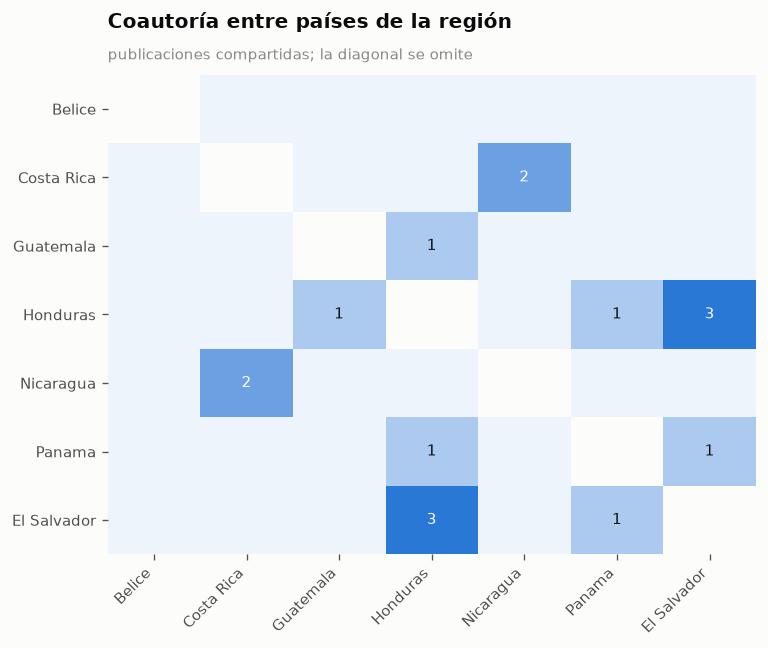

In [3]:
import numpy as np

fig, ax = plt.subplots(figsize=(6.5, 5.5))
datos = matriz.values.astype(float)
np.fill_diagonal(datos, np.nan)  # la diagonal es el total del pais, no colaboracion

imagen = ax.imshow(datos, cmap=viz.RAMPA_AZUL, aspect="auto")

ax.set_xticks(range(len(matriz)))
ax.set_yticks(range(len(matriz)))
ax.set_xticklabels(matriz.columns, rotation=45, ha="right")
ax.set_yticklabels(matriz.index)
ax.grid(visible=False)
viz.limpiar_ejes(ax, ("top", "right", "left", "bottom"))

maximo = np.nanmax(datos) if np.isfinite(datos).any() else 0
for i in range(len(matriz)):
    for j in range(len(matriz)):
        if i != j and datos[i, j] > 0:
            ax.annotate(f"{int(datos[i, j])}", (j, i), ha="center", va="center",
                        fontsize=9,
                        color="white" if datos[i, j] > maximo * 0.55 else viz.TINTA_PRIMARIA)

viz.titulo(ax, "Coautoría entre países de la región",
           "publicaciones compartidas; la diagonal se omite")
plt.tight_layout()
plt.show()

## Socios internacionales

Las afiliaciones marcadas como extranjeras se agrupan por el marcador que las identificó. Es una
aproximación: el marcador puede ser un país, una ciudad o una institución.

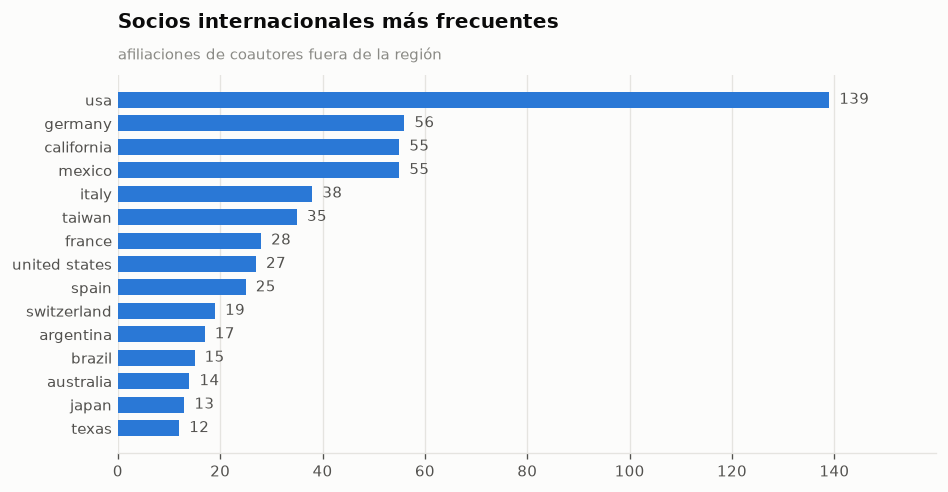

In [4]:
marcadores = [m.lower() for m in loader.foreign().foreign_markers]
extranjeras = aff[aff["is_foreign"] & aff["aff"].notna()].copy()

def primer_marcador(texto):
    bajo = str(texto).lower()
    encontrados = [m for m in marcadores if m in bajo]
    return max(encontrados, key=len) if encontrados else None

extranjeras["socio"] = extranjeras["aff"].apply(primer_marcador)
socios = extranjeras["socio"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(8, 4.2))
viz.barras_horizontales(ax, socios.index.tolist(), socios.values.tolist())
viz.titulo(ax, "Socios internacionales más frecuentes",
           "afiliaciones de coautores fuera de la región")
plt.tight_layout()
plt.show()

## Tamaño de los equipos

mediana de autores por publicacion: 4
publicaciones exclusivamente regionales: 56 (21%)
publicaciones con al menos un coautor extranjero: 217


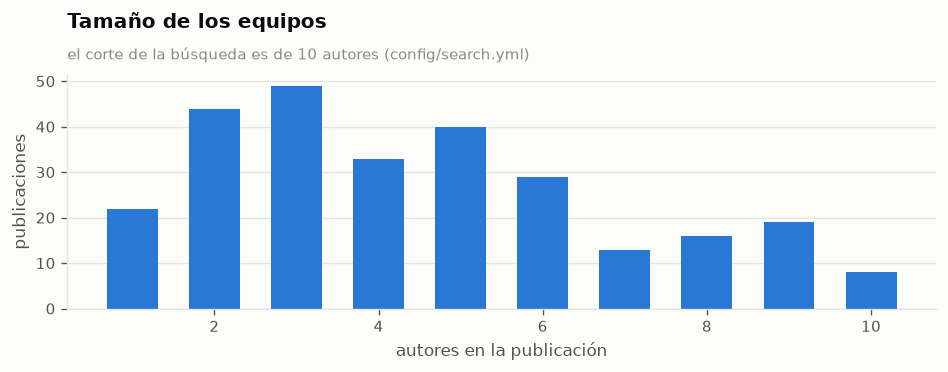

In [5]:
tam = aff.groupby("bibcode").size()
locales = region.groupby("bibcode").size().reindex(tam.index).fillna(0)
solo_region = (locales == tam).sum()

print(f"mediana de autores por publicacion: {tam.median():.0f}")
print(f"publicaciones exclusivamente regionales: {solo_region} ({solo_region / len(tam):.0%})")
print(f"publicaciones con al menos un coautor extranjero: {len(tam) - solo_region}")

fig, ax = plt.subplots(figsize=(8, 3.2))
distribucion = tam.value_counts().sort_index()
ax.bar(distribucion.index, distribucion.values, color=viz.SERIE_1, width=0.62)
ax.grid(axis="x", visible=False)
viz.limpiar_ejes(ax)
ax.set_xlabel("autores en la publicación")
ax.set_ylabel("publicaciones")
viz.titulo(ax, "Tamaño de los equipos",
           "el corte de la búsqueda es de 10 autores (config/search.yml)")
plt.tight_layout()
plt.show()